# Notebook 04: Quantum Emergence

**Goal:** Show explicitly that a qubit density matrix maps to a stochastic state,
that quantum evolution under $\sigma_x$ produces an indivisible process, and that in the
configuration basis the Born rule gives back the stochastic state itself.

By the end of this notebook you will be able to:
- Convert a density matrix to a stochastic state vector
- Verify that $\sigma_x$ qubit evolution is indivisible over a full period
- Compute measurement probabilities via the Born rule

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from isp.quantum import (
    density_matrix_to_stochastic_state,
    unitary_to_transition_matrix,
    make_qubit_sigmax_process,
    born_rule,
)
from isp.divisibility import check_divisibility, indivisibility_signature
from isp.visualization import plot_transition_matrix, plot_probability_evolution

## 1. Density Matrix → Stochastic State

A qubit density matrix $\rho$ encodes a probability distribution via its diagonal.
The diagonal entries $\rho_{ii}$ are the Born-rule probabilities for the
computational basis.

In [2]:
# Mixed qubit state: 70% |0⟩, 30% |1⟩, with coherences
rho = np.array([[0.7,  0.1 + 0.2j],
                [0.1 - 0.2j,  0.3]])

print("Density matrix ρ:")
print(rho)
print(f"\nTrace: {np.trace(rho).real:.4f}  (must be 1.0)")
print(f"Eigenvalues (must be ≥ 0): {np.linalg.eigvalsh(rho).round(4)}")

p = density_matrix_to_stochastic_state(rho)
print(f"\nStochastic state vector p = {p}")
print(f"Sum: {p.sum():.4f}")

Density matrix ρ:
[[0.7+0.j  0.1+0.2j]
 [0.1-0.2j 0.3+0.j ]]

Trace: 1.0000  (must be 1.0)
Eigenvalues (must be ≥ 0): [0.2 0.8]

Stochastic state vector p = [0.7 0.3]
Sum: 1.0000


## 2. Quantum Evolution Is Indivisible

The sigma_x qubit process is indivisible. Let's verify this formally and compute its
indivisibility signature. As notebook 03 explains, the signature is a detector, not a measure
of how quantum a process is: the value printed below comes from the sampled times closest to
$\omega t = \pi/2$ and $3\pi/2$ (each paired with $t = 2\pi$), where $\Gamma(t \leftarrow 0)$ is nearly singular, and it changes with the grid.

In [3]:
times = np.linspace(0, 2 * np.pi, 8).tolist()
proc = make_qubit_sigmax_process(omega=1.0, times=times)

result = check_divisibility(proc)
sig = indivisibility_signature(proc)

print(f"Divisible: {result['divisible']}")
print(f"Failure mode: {result['failure_mode']}")
print(f"Indivisibility signature: {sig:.4f}")

Divisible: False
Failure mode: negative_entries
Indivisibility signature: 1.7470


## 3. The Born Rule

Once we have a density matrix and a measurement operator, the Born rule
$P(\text{outcome}) = \text{Tr}(M \rho)$ gives the probability.

- **In the configuration basis it holds by construction.** For $M = |i\rangle\langle i|$, $\text{Tr}(M\rho) = \rho_{ii} = p_i$,
  the stochastic state itself (Barandes, arXiv:2302.10778, §3.2, eq. 16). The check below confirms exactly this.
- **For other observables it is a claim, not a definition.** Barandes argues that the textbook Born rule follows from the
  stochastic structure once the measuring device is modelled as a system with its own configurations (same paper, §4, eq. 78).
  This notebook does not test that part.

In [4]:
# Projective measurement onto |0⟩ and |1⟩
M0 = np.array([[1, 0], [0, 0]])
M1 = np.array([[0, 0], [0, 1]])

p0 = born_rule(rho, M0)
p1 = born_rule(rho, M1)

print(f"P(measure |0⟩) = {p0:.4f}")
print(f"P(measure |1⟩) = {p1:.4f}")
print(f"Sum (must be 1.0): {p0 + p1:.4f}")
print(f"\nStochastic state gives: {density_matrix_to_stochastic_state(rho)}")
print("(Born rule and stochastic diagonal agree ✓)")

P(measure |0⟩) = 0.7000
P(measure |1⟩) = 0.3000
Sum (must be 1.0): 1.0000

Stochastic state gives: [0.7 0.3]
(Born rule and stochastic diagonal agree ✓)


## 4. Evolving the Stochastic State

The process acts on probabilities: $p(t) = \Gamma(t \leftarrow 0)\,p(0)$ with $\Gamma = |U|^2$ entry by entry. That reproduces the
populations of the quantum state $\rho(t) = U\rho U^\dagger$ for every unitary when $\rho(0)$ is diagonal in the configuration basis,
which is how Barandes builds $\rho$ from a stochastic process (arXiv:2302.10778, eq. 17). With coherences it generally does not.
For this $\sigma_x$ evolution the difference is $-\sin(\omega t)\,\mathrm{Im}\,\rho_{01}$, so the real part of $\rho_{01} = 0.1 + 0.2i$
has no effect and the $0.2i$ part does. Below, the two routes are compared.

t = 1.8:  P(0) from Γ(t←0) p(0) = 0.4546   P(0) from the full ρ(t) = 0.2598
max |Γ route − ρ with coherences removed| = 2.2e-16
max |Γ route − full ρ|                    = 0.200


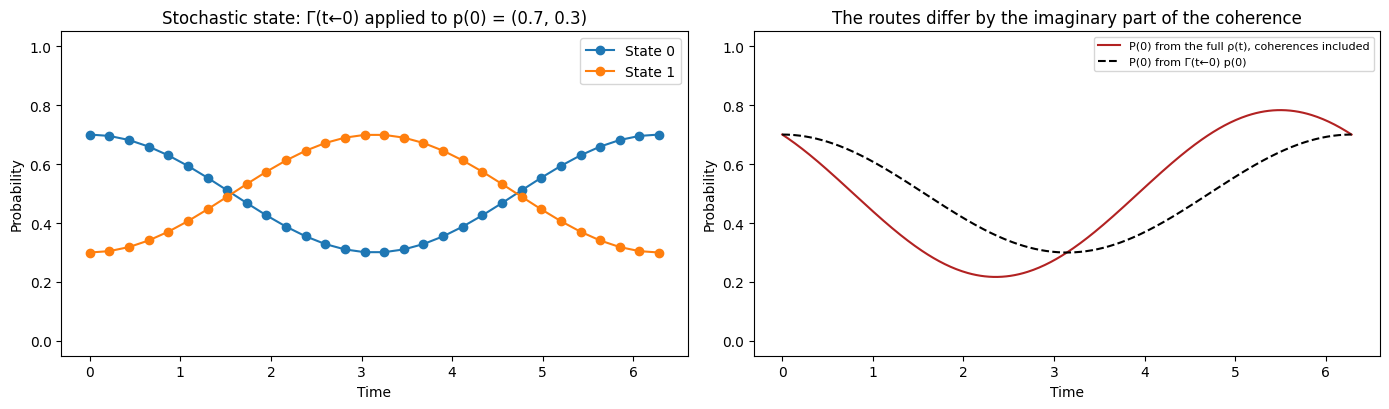

In [5]:
# Evolve the stochastic state, and compare with the populations of the full quantum state
from scipy.linalg import expm

omega = 1.0
times_dense = np.linspace(0, 2 * np.pi, 30).tolist()
proc_dense = make_qubit_sigmax_process(omega=omega, times=times_dense)
p0_vec = density_matrix_to_stochastic_state(rho)

sx = np.array([[0, 1], [1, 0]])
U_of = lambda t: expm(-1j * (omega / 2) * sx * t)                     # H = (ω/2) σ_x, as in make_qubit_sigmax_process
ts = np.linspace(0, 2 * np.pi, 400)
rho_diag = np.diag(np.diag(rho))                                       # same populations, coherences removed
via_gamma = np.array([unitary_to_transition_matrix(U_of(t)) @ p0_vec for t in ts])
full_rho = np.array([np.real(np.diag(U_of(t) @ rho @ U_of(t).conj().T)) for t in ts])
diag_rho = np.array([np.real(np.diag(U_of(t) @ rho_diag @ U_of(t).conj().T)) for t in ts])

t_check = 1.8
print(f"t = {t_check}:  P(0) from Γ(t←0) p(0) = {(unitary_to_transition_matrix(U_of(t_check)) @ p0_vec)[0]:.4f}"
      f"   P(0) from the full ρ(t) = {np.real(U_of(t_check) @ rho @ U_of(t_check).conj().T)[0, 0]:.4f}")
print(f"max |Γ route − ρ with coherences removed| = {np.abs(via_gamma - diag_rho).max():.1e}")
print(f"max |Γ route − full ρ|                    = {np.abs(via_gamma - full_rho).max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
plot_probability_evolution(proc_dense, p0_vec, title="Stochastic state: Γ(t←0) applied to p(0) = (0.7, 0.3)", ax=axes[0])
axes[1].plot(ts, full_rho[:, 0], color='firebrick', label='P(0) from the full ρ(t), coherences included')
axes[1].plot(ts, via_gamma[:, 0], '--', color='black', label='P(0) from Γ(t←0) p(0)')
axes[1].set_xlabel('Time'); axes[1].set_ylabel('Probability'); axes[1].set_ylim(-0.05, 1.05)
axes[1].set_title('The routes differ by the imaginary part of the coherence')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Summary

- Density matrices project onto stochastic states via their diagonal
- Qubit evolution under $\sigma_x$ produces an indivisible process: a bridge $t' \to t$ is valid exactly when $|\cos\omega t| \le |\cos\omega t'|$.
  The process restricted to $0 \le \omega t \le \pi/2$ is divisible (Pimenta, arXiv:2505.08785, eqs. 59–60), any window
  containing a revival of $|\cos\omega t|$ is not, and at $\omega t' = k\pi$, $\Gamma(t' \leftarrow 0)$ is a permutation
  and the process divides there exactly
- The Born rule holds by construction in the configuration basis; for other observables Barandes derives it from the
  stochastic structure plus a model of the measuring device (not tested here)
- $\Gamma(t \leftarrow 0)$ acting on the diagonal reproduces the quantum populations when $\rho(0)$ is diagonal; a $\rho$ with
  configuration-basis coherences carries information the present probabilities do not
- This is the core of Barandes' stochastic-quantum correspondence: a quantum system, measuring devices included, can be
  modelled as an indivisible stochastic process, and every indivisible stochastic process (finite configuration space)
  is a subsystem of a unistochastic one (arXiv:2309.03085)

**Next:** Notebook 05 builds the payoff — a double-slit model where
interference emerges from indivisibility.